d:\Programming\Projects\EventNexus\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Programming\Projects\EventNexus\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Programming\Projects\EventNexus\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


clusters: 31 | noise: 20%
{15: 178, 3: 152, 23: 74, 27: 74, 30: 65, 10: 63, 29: 63, 0: 56, 14: 54, 20: 54}


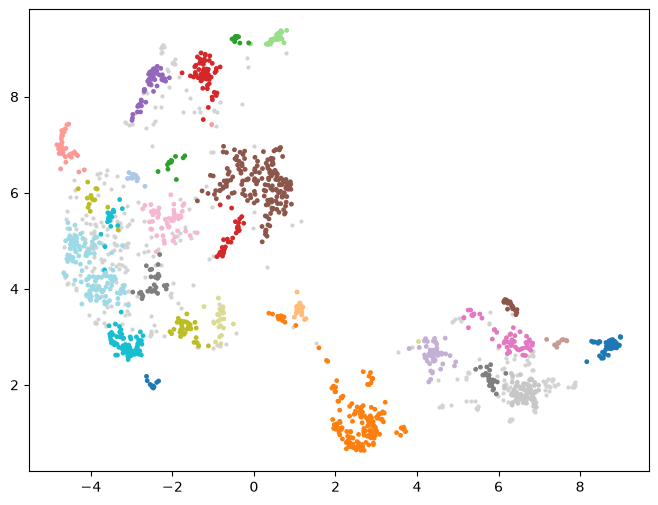


--- cluster 15 (178 events)
   On Sunday, in Karachi, Sindh, Pakistan, unidentified gunmen killed an activist of the Jeay Sindh Qaumi Mahaz (JSQM), identified as Younus Khan. Khan was killed 
   Assailants shot and killed a Traffic Police officer in Malir Town neighborhood, Karachi city, Sindh province, Pakistan. No group claimed responsibility for the 
   On Friday, in Garden Eastarea of Karachi, Sindh, Pakistan, two unidentified militants shot and killed a Paish Imam (prayer leader) of Dua Mosque. The prayer lea

--- cluster 3 (152 events)
   Two assailants on a motorcycle threw a grenade at the residence of Umar Zaib, a leader of the Awami National Party (ANP), in Mehran Town, Karachi city, Sindh pr
   Assailants threw a hand grenade at a gas station in Shershah area, Karachi city, Sindh province, Pakistan. One person was injured in the attack. No group has cl
   Assailants threw a grenade at a Rangers checkpost in Kati Pahari area, Karachi city, Sindh province, Pakistan. There wer

In [1]:
import numpy as np, pandas as pd
import umap
from sklearn.cluster import HDBSCAN
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/karachi_events_clean.parquet")
z = np.load("../data/processed/event_embeddings.npz")
V = z["vectors"]
assert (df["eventid"].to_numpy() == z["eventids"]).all()

U5 = umap.UMAP(n_components=5, n_neighbors=15, min_dist=0.0,
               metric="cosine", random_state=42).fit_transform(V)
U2 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
               metric="cosine", random_state=42).fit_transform(V)

lab = HDBSCAN(min_cluster_size=10).fit_predict(U5)
sizes = pd.Series(lab[lab >= 0]).value_counts()
print("clusters:", len(sizes), "| noise:", f"{(lab < 0).mean():.0%}")
print(sizes.head(10).to_dict())

plt.figure(figsize=(8, 6))
plt.scatter(*U2[lab < 0].T, s=4, c="lightgrey")
plt.scatter(*U2[lab >= 0].T, s=6, c=lab[lab >= 0], cmap="tab20")
plt.show()

df["cl"] = lab
for c in sizes.index[:3]:
    print(f"\n--- cluster {c} ({sizes[c]} events)")
    for t in df[df.cl == c].summary_clean.sample(3, random_state=0):
        print("  ", t[:160])

In [3]:
print(df.columns.tolist())

['eventid', 'iyear', 'imonth', 'iday', 'city', 'location', 'gname', 'guncertain1', 'claimed', 'attacktype1_txt', 'weaptype1_txt', 'weapsubtype1_txt', 'weapdetail', 'targtype1_txt', 'targsubtype1_txt', 'corp1', 'target1', 'nkill', 'nwound', 'success', 'suicide', 'multiple', 'related', 'doubtterr', 'summary', 'motive', 'scite1', 'scite2', 'scite3', 'dbsource', 'city_raw', 'date_approx', 'date', 'actor_known', 'summary_clean', 'dup_group', 'related_ids', 'related_in_scope', 'cl']


In [4]:
def top(sub, col):
    vc = sub[col].value_counts(normalize=True)
    return vc.index[0], round(vc.iloc[0], 2)

rows = []
for c in sizes.index:
    sub = df[df.cl == c]
    w, ws = top(sub, "weaptype1_txt")
    t, ts = top(sub, "targtype1_txt")
    a, as_ = top(sub, "attacktype1_txt")
    rows.append({"cluster": c, "n": len(sub),
                 "weapon": w[:18], "w%": ws, "target": t[:18], "t%": ts,
                 "attack": a[:18], "a%": as_,
                 "years": f"{sub.date.dt.year.min()}-{sub.date.dt.year.max()}"})

print(pd.DataFrame(rows).sort_values("n", ascending=False).to_string(index=False))

 cluster   n     weapon   w%             target   t%             attack   a%     years
      15 178   Firearms 0.97             Police 0.28      Armed Assault 0.83 2000-2020
       3 152 Explosives 0.99             Police 0.30  Bombing/Explosion 0.86 2001-2020
      23  74 Explosives 1.00 Private Citizens & 0.30  Bombing/Explosion 1.00 2006-2018
      27  74   Firearms 0.97             Police 0.91      Armed Assault 0.91 2006-2020
      30  65   Firearms 1.00 Private Citizens & 0.22      Armed Assault 0.82 2010-2019
      10  63   Firearms 0.98 Government (Genera 0.54      Armed Assault 0.92 2000-2018
      29  63   Firearms 0.95 Private Citizens & 0.40      Armed Assault 0.90 2010-2020
       0  56 Explosives 1.00            Unknown 0.39  Bombing/Explosion 1.00 2011-2020
      14  54 Explosives 1.00             Police 0.33  Bombing/Explosion 0.94 2002-2020
      20  54   Firearms 0.94 Government (Genera 0.22      Armed Assault 0.80 2003-2015
      11  45   Firearms 0.98 Religious Figu